In [1]:

#!/usr/bin/env python3
"""Interactive Hückel HOMO/LUMO visualization for Jupyter and Python."""

import numpy as np
import plotly.graph_objects as go
import plotly.io as pio

try:
    from IPython.display import display, HTML
    from IPython import get_ipython

    _ip = get_ipython()
    IN_NOTEBOOK = _ip is not None and "IPKernelApp" in _ip.config
except (ImportError, AttributeError):
    IN_NOTEBOOK = False


def visualize_huckel(
    H,
    electron_count=None,
    positions=None,
    grid_size=45,
    sigma=0.65,
    isovalue=0.12,
):
    """
    Calculate and visualize the Hückel HOMO and LUMO.

    Parameters
    ----------
    H : array-like, shape (N, N)
        Symmetric Hückel Hamiltonian.
    electron_count : int, optional
        Number of pi electrons. Defaults to N (one per site).
        Assumes a closed-shell, spin-paired ground state.
    positions : array-like, shape (N, 3), optional
        Coordinates of the atomic sites. Defaults to a planar ring.
    grid_size : int
        Number of grid points per axis.
    sigma : float
        Width of the approximate atomic p orbital.
    isovalue : float
        Surface threshold as a fraction of peak wavefunction magnitude.

    Returns
    -------
    energies : ndarray
        Molecular orbital energies, in ascending order.
    coefficients : ndarray
        MO coefficients; columns correspond to energies.
    """

    H = np.asarray(H, dtype=float)

    if H.ndim != 2 or H.shape[0] != H.shape[1]:
        raise ValueError("H must be a square matrix.")
    if not np.isfinite(H).all():
        raise ValueError("H must contain only finite values.")
    if not np.allclose(H, H.T, atol=1e-10):
        raise ValueError("H must be symmetric.")
    if sigma <= 0 or grid_size < 10:
        raise ValueError("sigma must be positive and grid_size >= 10.")
    if not 0 < isovalue < 1:
        raise ValueError("isovalue must be between 0 and 1.")

    n = H.shape[0]
    if n < 2:
        raise ValueError("At least two orbitals are required.")

    if electron_count is None:
        electron_count = n

    if not isinstance(electron_count, (int, np.integer)):
        raise ValueError("electron_count must be an integer.")
    if not 2 <= electron_count <= 2 * n - 2:
        raise ValueError("electron_count must be between 2 and 2N-2.")
    if electron_count % 2:
        raise ValueError(
            "This implementation assumes an even number of pi electrons."
        )

    # Solve H c = E c.
    energies, coefficients = np.linalg.eigh(H)

    # Closed-shell filling: two electrons per orbital.
    homo_idx = electron_count // 2 - 1
    lumo_idx = homo_idx + 1

    # Default visualization geometry: regular planar ring.
    if positions is None:
        radius = max(1.0, n / (2 * np.pi))
        theta = 2 * np.pi * np.arange(n) / n
        positions = np.column_stack((
            radius * np.cos(theta),
            radius * np.sin(theta),
            np.zeros(n),
        ))
    else:
        positions = np.asarray(positions, dtype=float)

    if positions.shape != (n, 3):
        raise ValueError(f"positions must have shape ({n}, 3).")
    if not np.isfinite(positions).all():
        raise ValueError("positions must contain only finite values.")

    # Construct a 3D grid around the molecule.
    margin = 3 * sigma
    lower = positions.min(axis=0) - margin
    upper = positions.max(axis=0) + margin

    axes = [
        np.linspace(lower[i], upper[i], grid_size)
        for i in range(3)
    ]
    X, Y, Z = np.meshgrid(*axes, indexing="ij")

    # Approximate each site orbital as a Gaussian p_z function.
    # psi(r) = sum_i c_i * (z-z_i) * exp(-|r-R_i|^2/(2*sigma^2))
    def wavefunction(coeff):
        psi = np.zeros_like(X)

        for c, (x0, y0, z0) in zip(coeff, positions):
            dx = X - x0
            dy = Y - y0
            dz = Z - z0

            r2 = dx**2 + dy**2 + dz**2
            psi += c * dz * np.exp(-r2 / (2 * sigma**2))

        return psi

    # Display each orbital as red/blue phase isosurfaces.
    def make_figure(psi, name, idx):
        peak = np.max(np.abs(psi))
        if peak < 1e-12:
            raise ValueError(f"{name} wavefunction is numerically zero.")

        level = isovalue * peak
        flatten = lambda a: a.ravel()

        fig = go.Figure()

        for sign, color, label in [
            (1, "red", "Positive phase"),
            (-1, "blue", "Negative phase"),
        ]:
            fig.add_trace(go.Isosurface(
                x=flatten(X),
                y=flatten(Y),
                z=flatten(Z),
                value=flatten(psi),
                isomin=level if sign == 1 else -peak,
                isomax=peak if sign == 1 else -level,
                surface_count=1,
                colorscale=[[0, color], [1, color]],
                showscale=False,
                opacity=0.65,
                caps=dict(x_show=False, y_show=False, z_show=False),
                name=label,
                hoverinfo="skip",
            ))

        # Draw site-to-site couplings as bonds.
        for i in range(n):
            for j in range(i + 1, n):
                if abs(H[i, j]) > 1e-10:
                    fig.add_trace(go.Scatter3d(
                        x=[positions[i, 0], positions[j, 0]],
                        y=[positions[i, 1], positions[j, 1]],
                        z=[positions[i, 2], positions[j, 2]],
                        mode="lines",
                        line=dict(color="gray", width=4),
                        showlegend=False,
                        hoverinfo="skip",
                    ))

        fig.add_trace(go.Scatter3d(
            x=positions[:, 0],
            y=positions[:, 1],
            z=positions[:, 2],
            mode="markers+text",
            text=[str(i + 1) for i in range(n)],
            textposition="top center",
            marker=dict(size=5, color="black"),
            name="Sites",
        ))

        fig.update_layout(
            title=f"{name} (MO {idx + 1}) | E = {energies[idx]:.4f}",
            scene=dict(
                aspectmode="data",
                xaxis_title="X",
                yaxis_title="Y",
                zaxis_title="Z",
            ),
            margin=dict(l=0, r=0, t=50, b=0),
            height=600,
        )

        if IN_NOTEBOOK:
            display(fig)
        else:
            fig.show()

    print(f"Number of sites: {n}")
    print(f"Pi electrons: {electron_count}")
    print(f"HOMO energy: {energies[homo_idx]:.6f}")
    print(f"LUMO energy: {energies[lumo_idx]:.6f}")
    print(f"HOMO-LUMO gap: {energies[lumo_idx] - energies[homo_idx]:.6f}")

    make_figure(
        wavefunction(coefficients[:, homo_idx]), "HOMO", homo_idx
    )
    make_figure(
        wavefunction(coefficients[:, lumo_idx]), "LUMO", lumo_idx
    )

    return energies, coefficients

def pureCirculantCreator(N:int) -> np.array:
    H = np.zeros((N, N))
     
    for i in range(N):
        j = (i + 1) % N
        H[i, j] = H[j, i] = -1.0
    
    return H 

# Example: benzene Hückel Hamiltonian
if __name__ == "__main__":
    H = pureCirculantCreator(N=6)
    print(H)

    energies, orbitals = visualize_huckel(H)


[[ 0. -1.  0.  0.  0. -1.]
 [-1.  0. -1.  0.  0.  0.]
 [ 0. -1.  0. -1.  0.  0.]
 [ 0.  0. -1.  0. -1.  0.]
 [ 0.  0.  0. -1.  0. -1.]
 [-1.  0.  0.  0. -1.  0.]]
Number of sites: 6
Pi electrons: 6
HOMO energy: -1.000000
LUMO energy: 1.000000
HOMO-LUMO gap: 2.000000


In [2]:
#Benzene Hückel Matrix
HCycloButene = pureCirculantCreator(N=2)
print(HCycloButene)
energies, orbitals = visualize_huckel(HCycloButene)

[[ 0. -1.]
 [-1.  0.]]
Number of sites: 2
Pi electrons: 2
HOMO energy: -1.000000
LUMO energy: 1.000000
HOMO-LUMO gap: 2.000000


Benzene Hückel matrix:
 [[ 0. -1.  0.  0.  0. -1.]
 [-1.  0. -1.  0.  0.  0.]
 [ 0. -1.  0. -1.  0.  0.]
 [ 0.  0. -1.  0. -1.  0.]
 [ 0.  0.  0. -1.  0. -1.]
 [-1.  0.  0.  0. -1.  0.]]
Sites: 6 | Pi electrons: 6
HOMO energy: -1.000000
LUMO energy: 1.000000
HOMO-LUMO gap: 2.000000


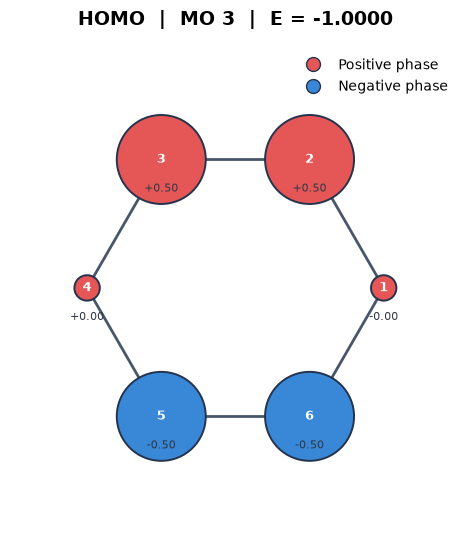

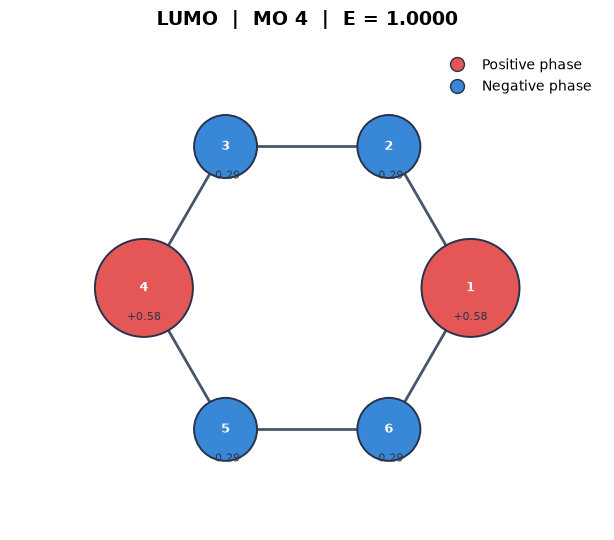

In [ ]:

#!/usr/bin/env python3
"""Hückel Hamiltonian construction and orbital visualization toolkit."""

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Circle
import plotly.graph_objects as go

try:
    from IPython import get_ipython
    from IPython.display import display

    _ip = get_ipython()
    IN_NOTEBOOK = _ip is not None and "IPKernelApp" in _ip.config
except (ImportError, AttributeError):
    IN_NOTEBOOK = False


# ============================================================
# 1. HAMILTONIAN CONSTRUCTORS
# ============================================================

def _site_energies(N, alpha=0.0, hetero_atoms=None):
    """Build diagonal Coulomb integrals. hetero_atoms maps index -> alpha."""
    if np.isscalar(alpha):
        diagonal = np.full(N, float(alpha))
    else:
        diagonal = np.asarray(alpha, dtype=float).copy()
        if diagonal.shape != (N,):
            raise ValueError("alpha must be a scalar or length-N array.")

    for i, value in (hetero_atoms or {}).items():
        if not 0 <= i < N:
            raise IndexError(f"Heteroatom index {i} outside 0..{N-1}.")
        diagonal[i] = float(value)

    return diagonal


def _couplings(N, beta=-1.0, couplings=None, count=None):
    """Return bond couplings, accepting a scalar or explicit sequence."""
    count = N - 1 if count is None else count

    values = beta if couplings is None else couplings
    if np.isscalar(values):
        return np.full(count, float(values))

    values = np.asarray(values, dtype=float)
    if values.shape != (count,):
        raise ValueError(f"Expected {count} bond couplings.")
    return values


def linear_toeplitz_creator(
    N,
    beta=-1.0,
    alpha=0.0,
    hetero_atoms=None,
    couplings=None,
):
    """
    Linear conjugated chain.

    beta: uniform nearest-neighbor resonance integral.
    alpha: uniform or site-specific Coulomb integrals.
    hetero_atoms: {site_index: Coulomb_integral}.
    couplings: optional length-(N-1) bond integral array.
    """
    if N < 2:
        raise ValueError("N must be >= 2.")

    H = np.diag(_site_energies(N, alpha, hetero_atoms))
    bonds = _couplings(N, beta, couplings)

    for i, b in enumerate(bonds):
        H[i, i + 1] = H[i + 1, i] = b

    return H


def pureCirculantCreator(
    N,
    beta=-1.0,
    alpha=0.0,
    hetero_atoms=None,
    couplings=None,
):
    """Cyclic conjugated system with periodic boundary conditions."""
    if N < 3:
        raise ValueError("A cyclic system requires N >= 3.")

    H = np.diag(_site_energies(N, alpha, hetero_atoms))
    bonds = _couplings(N, beta, couplings, count=N)

    for i in range(N):
        j = (i + 1) % N
        H[i, j] = H[j, i] = bonds[i]

    return H


def mobius_creator(
    N,
    beta=-1.0,
    alpha=0.0,
    hetero_atoms=None,
    couplings=None,
    twist_sign=-1,
):
    """
    Ring with a sign-reversed boundary coupling (Möbius Hückel model).

    twist_sign=-1 reverses the sign of the closing bond relative to beta.
    This encodes a simple signed-boundary-condition model, not a
    geometry-resolved twisted molecular structure.
    """
    if N < 3:
        raise ValueError("A Möbius ring requires N >= 3.")
    if twist_sign not in (-1, 1):
        raise ValueError("twist_sign must be +1 or -1.")

    H = np.diag(_site_energies(N, alpha, hetero_atoms))
    bonds = _couplings(N, beta, couplings, count=N)

    for i in range(N - 1):
        H[i, i + 1] = H[i + 1, i] = bonds[i]

    # Change the sign of the closing bond relative to an ordinary ring.
    closing_beta = twist_sign * bonds[-1]
    H[0, N - 1] = H[N - 1, 0] = closing_beta

    return H


# Convenient alternative spelling.
toeplitz_creator = linear_toeplitz_creator


# ============================================================
# 2. DEFAULT GEOMETRY
# ============================================================

def _default_positions(H):
    """Infer a simple line or ring layout from the matrix connectivity."""
    N = len(H)
    adjacency = np.abs(H - np.diag(np.diag(H))) > 1e-10
    degree = adjacency.sum(axis=0)
    edge_count = np.triu(adjacency, 1).sum()

    # Path graph: draw a linear conjugated chain.
    if (
        edge_count == N - 1
        and np.all(degree <= 2)
        and np.count_nonzero(degree == 1) == 2
    ):
        x = np.arange(N, dtype=float) * 1.4
        x -= x.mean()
        return np.column_stack([x, np.zeros(N), np.zeros(N)])

    # Default for cyclic and other connected systems: planar ring.
    radius = max(1.0, 1.4 / (2 * np.sin(np.pi / N)))
    theta = 2 * np.pi * np.arange(N) / N

    return np.column_stack([
        radius * np.cos(theta),
        radius * np.sin(theta),
        np.zeros(N),
    ])


# ============================================================
# 3. PUBLICATION-STYLE 2D ORBITAL FIGURES
# ============================================================

def _plot_orbital_2d(
    H, positions, coefficients, energy, name, index,
    output_dir=None,
):
    """
    Plot MO coefficients as phase-colored, size-scaled atomic sites.
    Produces a vector-friendly figure suitable for publication.
    """
    N = len(H)
    coeff = coefficients[:, index]
    max_coeff = max(np.max(np.abs(coeff)), 1e-12)

    fig, ax = plt.subplots(figsize=(8, 5.5))

    # Bonds first, so they sit behind the orbital sites.
    for i in range(N):
        for j in range(i + 1, N):
            if abs(H[i, j]) > 1e-10:
                ax.plot(
                    [positions[i, 0], positions[j, 0]],
                    [positions[i, 1], positions[j, 1]],
                    color="#48566A",
                    linewidth=2.0,
                    zorder=1,
                )

    # Each site is scaled by |c_i| and colored by coefficient phase.
    for i, (x, y, _) in enumerate(positions):
        c = coeff[i]
        fraction = abs(c) / max_coeff
        radius = 0.12 + 0.30 * fraction
        color = "#E45756" if c >= 0 else "#3987D7"

        ax.add_patch(Circle(
            (x, y),
            radius=radius,
            facecolor=color,
            edgecolor="#26334D",
            linewidth=1.4,
            zorder=3,
        ))

        ax.text(
            x, y, str(i + 1),
            ha="center", va="center",
            color="white", fontsize=9, fontweight="bold",
            zorder=4,
        )

        # Coefficient below each site.
        ax.annotate(
            f"{c:+.2f}",
            (x, y),
            xytext=(0, -17),
            textcoords="offset points",
            ha="center", va="top",
            fontsize=8, color="#303846",
        )

    legend = [
        Line2D(
            [0], [0], marker="o", linestyle="",
            markerfacecolor="#E45756", markeredgecolor="#26334D",
            markersize=10, label="Positive phase",
        ),
        Line2D(
            [0], [0], marker="o", linestyle="",
            markerfacecolor="#3987D7", markeredgecolor="#26334D",
            markersize=10, label="Negative phase",
        ),
    ]
    ax.legend(handles=legend, frameon=False, loc="best")

    ax.set_title(
        f"{name}  |  MO {index + 1}  |  E = {energy:.4f}",
        fontsize=14, fontweight="bold", pad=15,
    )
    ax.set_aspect("equal")
    ax.axis("off")
    ax.margins(0.2)
    fig.tight_layout()

    if output_dir is not None:
        output_dir = Path(output_dir)
        output_dir.mkdir(parents=True, exist_ok=True)
        stem = name.lower()
        fig.savefig(
            output_dir / f"{stem}_2d.png",
            dpi=400, bbox_inches="tight", facecolor="white",
        )
        fig.savefig(
            output_dir / f"{stem}_2d.pdf",
            bbox_inches="tight", facecolor="white",
        )

    if IN_NOTEBOOK:
        display(fig)
        plt.close(fig)
    else:
        plt.show()


# ============================================================
# 4. INTERACTIVE 3D ORBITAL FIGURES
# ============================================================

def _plot_orbital_3d(
    H, positions, coefficients, energy, name, index,
    grid_size=45, sigma=0.65, isovalue=0.12,
):
    """Render an approximate p-orbital expansion as 3D isosurfaces."""
    margin = 3 * sigma
    lower = positions.min(axis=0) - margin
    upper = positions.max(axis=0) + margin

    axes = [
        np.linspace(lower[k], upper[k], grid_size)
        for k in range(3)
    ]
    X, Y, Z = np.meshgrid(*axes, indexing="ij")

    psi = np.zeros_like(X)
    coeff = coefficients[:, index]

    for c, (x0, y0, z0) in zip(coeff, positions):
        dx, dy, dz = X - x0, Y - y0, Z - z0
        psi += c * dz * np.exp(
            -(dx**2 + dy**2 + dz**2) / (2 * sigma**2)
        )

    peak = np.max(np.abs(psi))
    if peak < 1e-12:
        raise ValueError(f"{name} wavefunction is numerically zero.")

    level = isovalue * peak
    flatten = lambda a: a.ravel()

    fig = go.Figure()

    for color, label, mask_sign in [
        ("red", "Positive phase", 1),
        ("blue", "Negative phase", -1),
    ]:
        fig.add_trace(go.Isosurface(
            x=flatten(X), y=flatten(Y), z=flatten(Z),
            value=flatten(psi),
            isomin=level if mask_sign == 1 else -peak,
            isomax=peak if mask_sign == 1 else -level,
            surface_count=1,
            colorscale=[[0, color], [1, color]],
            showscale=False,
            opacity=0.65,
            caps=dict(x_show=False, y_show=False, z_show=False),
            name=label,
            hoverinfo="skip",
        ))

    # Bonds inferred from the nonzero off-diagonal Hamiltonian entries.
    for i in range(len(H)):
        for j in range(i + 1, len(H)):
            if abs(H[i, j]) > 1e-10:
                fig.add_trace(go.Scatter3d(
                    x=[positions[i, 0], positions[j, 0]],
                    y=[positions[i, 1], positions[j, 1]],
                    z=[positions[i, 2], positions[j, 2]],
                    mode="lines",
                    line=dict(color="#48566A", width=5),
                    showlegend=False,
                    hoverinfo="skip",
                ))

    fig.add_trace(go.Scatter3d(
        x=positions[:, 0],
        y=positions[:, 1],
        z=positions[:, 2],
        mode="markers+text",
        text=[str(i + 1) for i in range(len(H))],
        textposition="top center",
        marker=dict(size=5, color="#26334D"),
        name="Sites",
    ))

    fig.update_layout(
        title=f"{name} | MO {index + 1} | E = {energy:.4f}",
        scene=dict(
            aspectmode="data",
            xaxis_title="X",
            yaxis_title="Y",
            zaxis_title="Z",
        ),
        margin=dict(l=0, r=0, t=50, b=0),
        height=600,
    )

    if IN_NOTEBOOK:
        display(fig)
    else:
        fig.show()


# ============================================================
# 5. MAIN ENTRY POINT
# ============================================================

def visualize_huckel(
    H,
    electron_count=None,
    positions=None,
    grid_size=45,
    sigma=0.65,
    isovalue=0.12,
    output_dir="huckel_figures",
    static_2d=True,
    interactive_3d=True,
):
    """
    Compute and visualize HOMO/LUMO for a symmetric Hückel matrix.

    Default electron count: N.
    Closed-shell and odd-electron systems are supported using
    simple Aufbau filling; open-shell spin physics is not modeled.

    Returns
    -------
    energies : ndarray, shape (N,)
    coefficients : ndarray, shape (N, N)
        Eigenvectors are stored as columns.
    """
    H = np.asarray(H, dtype=float)

    if H.ndim != 2 or H.shape[0] != H.shape[1]:
        raise ValueError("H must be a square matrix.")
    if not np.isfinite(H).all():
        raise ValueError("H must contain finite values.")
    if not np.allclose(H, H.T, atol=1e-10):
        raise ValueError("H must be symmetric.")
    if grid_size < 10 or sigma <= 0:
        raise ValueError("grid_size must be >= 10 and sigma > 0.")
    if not 0 < isovalue < 1:
        raise ValueError("isovalue must be between 0 and 1.")

    N = len(H)
    if N < 2:
        raise ValueError("At least two sites are required.")

    if electron_count is None:
        electron_count = N

    if not isinstance(electron_count, (int, np.integer)):
        raise ValueError("electron_count must be an integer.")
    if not 1 <= electron_count <= 2 * N - 1:
        raise ValueError("electron_count must be between 1 and 2N-1.")

    energies, coefficients = np.linalg.eigh(H)

    # Two electrons per orbital, with a singly occupied HOMO if odd.
    homo_idx = (electron_count - 1) // 2
    lumo_idx = electron_count // 2

    if positions is None:
        positions = _default_positions(H)
    else:
        positions = np.asarray(positions, dtype=float)

    if positions.shape != (N, 3):
        raise ValueError(f"positions must have shape ({N}, 3).")
    if not np.isfinite(positions).all():
        raise ValueError("positions must contain finite values.")

    print(f"Sites: {N} | Pi electrons: {electron_count}")
    print(f"HOMO energy: {energies[homo_idx]:.6f}")
    print(f"LUMO energy: {energies[lumo_idx]:.6f}")
    print(f"HOMO-LUMO gap: "
          f"{energies[lumo_idx] - energies[homo_idx]:.6f}")

    for name, idx in [("HOMO", homo_idx), ("LUMO", lumo_idx)]:
        if static_2d:
            _plot_orbital_2d(
                H, positions, coefficients, energies[idx],
                name, idx, output_dir=output_dir,
            )

        if interactive_3d:
            _plot_orbital_3d(
                H, positions, coefficients, energies[idx],
                name, idx, grid_size=grid_size,
                sigma=sigma, isovalue=isovalue,
            )

    return energies, coefficients


In [4]:
HMobius = np.array([
    [0, -1, 0, 0, 0, 0, 0, 0, 1],
    [-1, 0, -1, 0, 0, 0, 0, 0, 0],
    [0, -1, 0, -1, 0, 0, 0, 0, 0],
    [0, 0, -1, 0, -1, 0, 0, 0, 0],
    [0, 0, 0, -1, 0, -1, 0, 0, 0],
    [0, 0, 0, 0, -1, 0, -1, 0, 0],
    [0, 0, 0, 0, 0, -1, 0, -1, 0],
    [0, 0, 0, 0, 0, 0, -1, 0, -1],
    [1, 0, 0, 0, 0, 0, 0, -1, 0]
], dtype=float)


In [5]:

HHeteroatoms = np.array([
    [-1.5, -0.8, 0.0, 0.0, -0.8],
    [-0.8, 0.0, -1.0, 0.0, 0.0],
    [0.0, -1.0, 0.0, -1.0, 0.0],
    [0.0, 0.0, -1.0, 0.0, -1.0],
    [0.8, 0.0, 0.0, -1.0, 0.0]
])

In [6]:
HLinButene = np.array([
    [0,-1,0,0],
    [-1,0,-1,0],
    [0,-1,0,-1],
    [0,0,0,-1],
])

In [7]:
HBenzene = np.array([
    [0,-1,0,0,0,-1],
    [-1,0,-1,0,0,0],
    [0,-1,0,-1,0,0],
    [0,0,-1,0,-1,0],
    [0,0,0,-1,0,-1],
    [-1,0,0,0,0,0],
], dtype=float)

In [8]:
energies, orbitals = visualize_huckel(HBenzene)

ValueError: H must be symmetric.

In [ ]:
energies, orbitals = visualize_huckel(HMobius)

In [ ]:
energies, orbitals = visualize_huckel(HLinButene)

In [ ]:
energies, orbitals = visualize_huckel(HHeteroatoms)